In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta

In [63]:
n_samples = 50000
mu = 0
sigma = 1
lognormal_data = np.random.lognormal(mu, sigma, n_samples) 
PD_mean = np.exp(0 + 0.5 * 1**2)
PD_sigma = np.sqrt((np.exp(1**2) - 1) * np.exp(2 * 0 + 1**2))

MIN = np.min(lognormal_data)
MEDIANE = np.median(lognormal_data)
MAX= np.max(lognormal_data) 

def calculate_pd_params(outstanding_amount):
    PD_mean = np.exp(0 + 0.5 * (1 + outstanding_amount / 100000))
    PD_sigma = np.sqrt((np.exp(1**2) - 1) * np.exp(2 * 0 + (1 + outstanding_amount / 100000)**2))
    return PD_mean, PD_sigma
loan_data = {
    'Loan 1': 10000,
    'Loan 2': 50000,
    'Loan 3': 20000
}
loan_params = {}

for loan, outstanding_amount in loan_data.items():
    PD_mean, PD_sigma = calculate_pd_params(outstanding_amount)

    loan_params[loan] = {
        'EPD': outstanding_amount,  
        'PD-mean': PD_mean,         
        'PD-sigma': PD_sigma,        
        'LGD-min': MIN,              
        'LGD-mode': MEDIANE,        
        'LGD-max': MAX               
    }
    df = pd.DataFrame(loan_params).T  
print(df)

            EPD   PD-mean  PD-sigma   LGD-min  LGD-mode    LGD-max
Loan 1  10000.0  1.733253  2.400465  0.022324  0.998789  48.568337
Loan 2  50000.0  2.117000  4.037648  0.022324  0.998789  48.568337
Loan 3  20000.0  1.822119  2.693018  0.022324  0.998789  48.568337


In [64]:
# Новая таблица
data = []

for loan, params in loan_params.items():
    EAD = params['EPD']
    PD = params['PD-mean']
    LGD = params['LGD-mode']
    
    EL = EAD * PD * LGD
    
    data.append([
        EAD,    
        PD,    
        LGD,   
        EL     
    ])

new_df = pd.DataFrame(data, columns=['EPD', 'PD', 'LGD', 'EL'], index=loan_params.keys())

print(new_df)


          EPD        PD       LGD             EL
Loan 1  10000  1.733253  0.998789   17311.543472
Loan 2  50000  2.117000  0.998789  105721.834721
Loan 3  20000  1.822119  0.998789   36398.250571


95-й перцентиль: 5.172785276084494


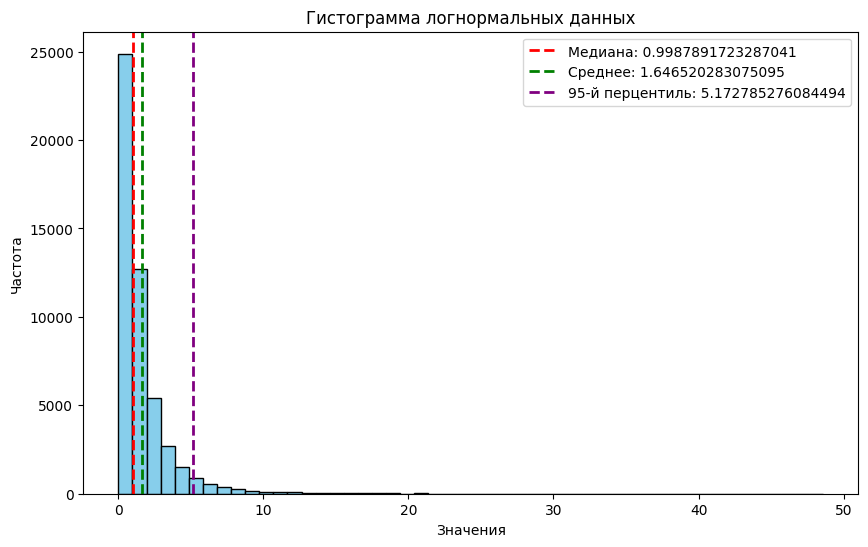

In [65]:
median_value = np.median(lognormal_data)
mean_value = np.mean(lognormal_data)
perc = np.percentile(lognormal_data, 95)

plt.figure(figsize=(10, 6))
plt.hist(lognormal_data, bins=50, color='skyblue', edgecolor='black')
plt.axvline(median_value, color='red', linestyle='dashed', linewidth=2, label=f'Медиана: {median_value}')
plt.axvline(mean_value, color='green', linestyle='dashed', linewidth=2, label=f'Среднее: {mean_value}')
plt.axvline(perc, color='purple', linestyle='dashed', linewidth=2, label=f'95-й перцентиль: {perc}')

plt.title('Гистограмма логнормальных данных')
plt.xlabel('Значения')
plt.ylabel('Частота')
plt.legend()

print(f"95-й перцентиль: {perc}")